In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.model_selection import train_test_split

In [13]:
# Load dataset
df = pd.read_csv(
    'data/archive_week10.zip',
    engine='python',
    on_bad_lines='skip'
)

# Remove duplicates
df = df.drop_duplicates()

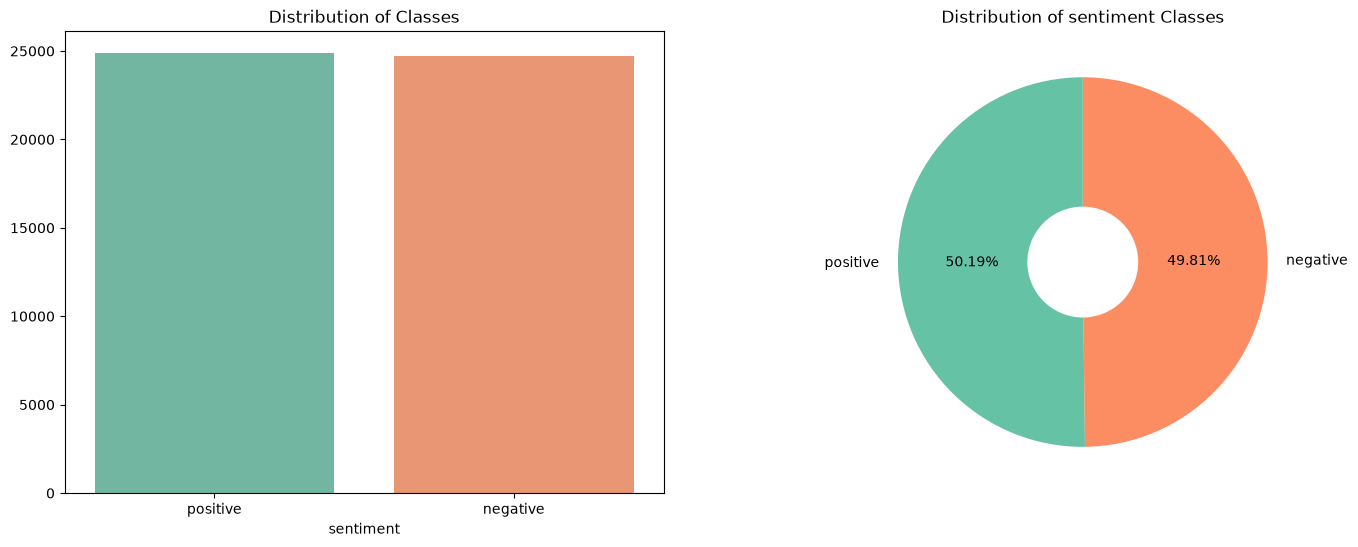

In [15]:
# Plot sentiment distribution
plt.figure(figsize=(17, 6))
counts = df['sentiment'].value_counts()

plt.subplot(1, 2, 1)
sns.barplot(
    x=counts.index,
    y=counts.values,
    hue=counts.index,
    palette='Set2',
    legend=False
)
plt.title("Distribution of Classes")

plt.subplot(1, 2, 2)
plt.pie(counts, labels=counts.index, autopct='%.2f%%',
        colors=sns.color_palette('Set2', 2), startangle=90,
        wedgeprops={'width': 0.7})
plt.title("Distribution of sentiment Classes")

plt.show()

In [10]:
# Convert sentiment into numbers
y = df['sentiment'].map({'positive': 1, 'negative': 0})
X = df['review']

# Tokenize and pad reviews
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(X)
X = pad_sequences(tokenizer.texts_to_sequences(X), maxlen=100)

In [11]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Build LSTM model
model = Sequential([
    Embedding(5000, 32),
    LSTM(32),
    Dense(1, activation='sigmoid')
])

# Compile and train
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history = model.fit(
    X_train, y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/3
496/496 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.8014 - loss: 0.4206 - val_accuracy: 0.8428 - val_loss: 0.3959
Epoch 2/3
496/496 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.8802 - loss: 0.2903 - val_accuracy: 0.8543 - val_loss: 0.3329
Epoch 3/3
496/496 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.8953 - loss: 0.2545 - val_accuracy: 0.8560 - val_loss: 0.3333


In [12]:
# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

310/310 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8557 - loss: 0.3283
Test Accuracy: 0.8557023406028748
